# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import CaliforniaFloodDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Original image

In [ ]:
dataset_config = {
    "data_dir" : "./data/california_flood/UiT_HCD_California_2017.mat",
    "selection": "rgb"
}
dataset = CaliforniaFloodDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 1


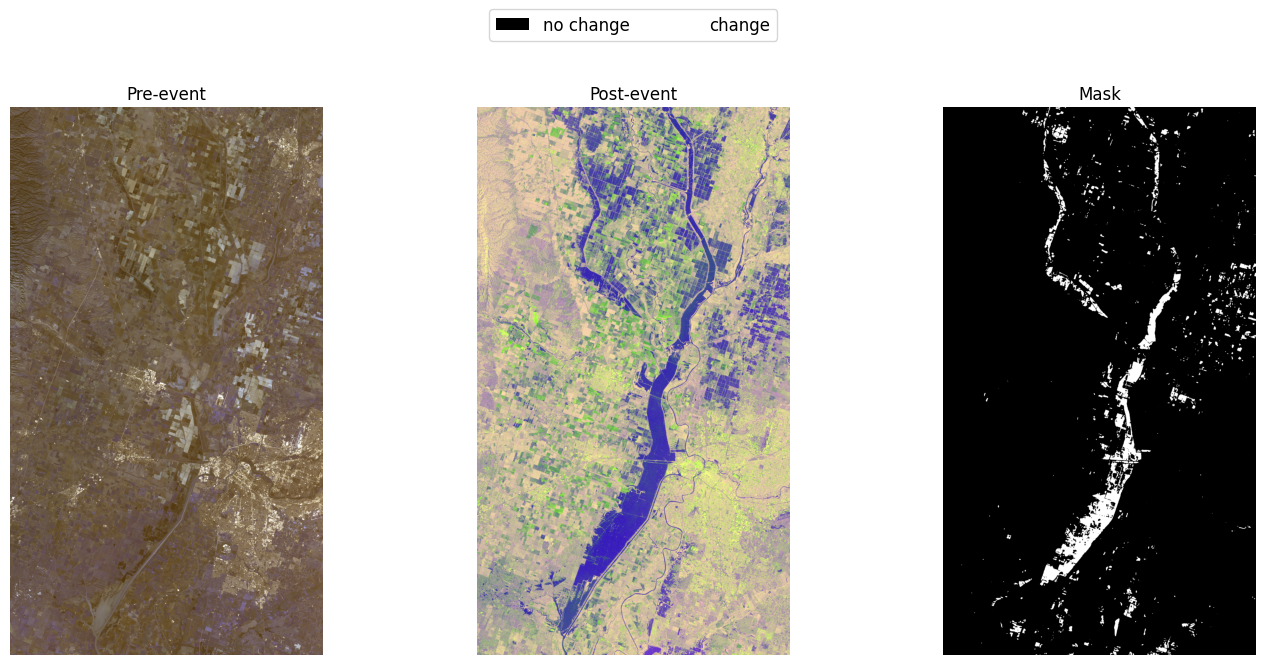

In [11]:
dataset.show_image(0);

In [11]:
dataset.data_distribution_table()

,Number of pixels
no change,6694073.0
change,305927.0


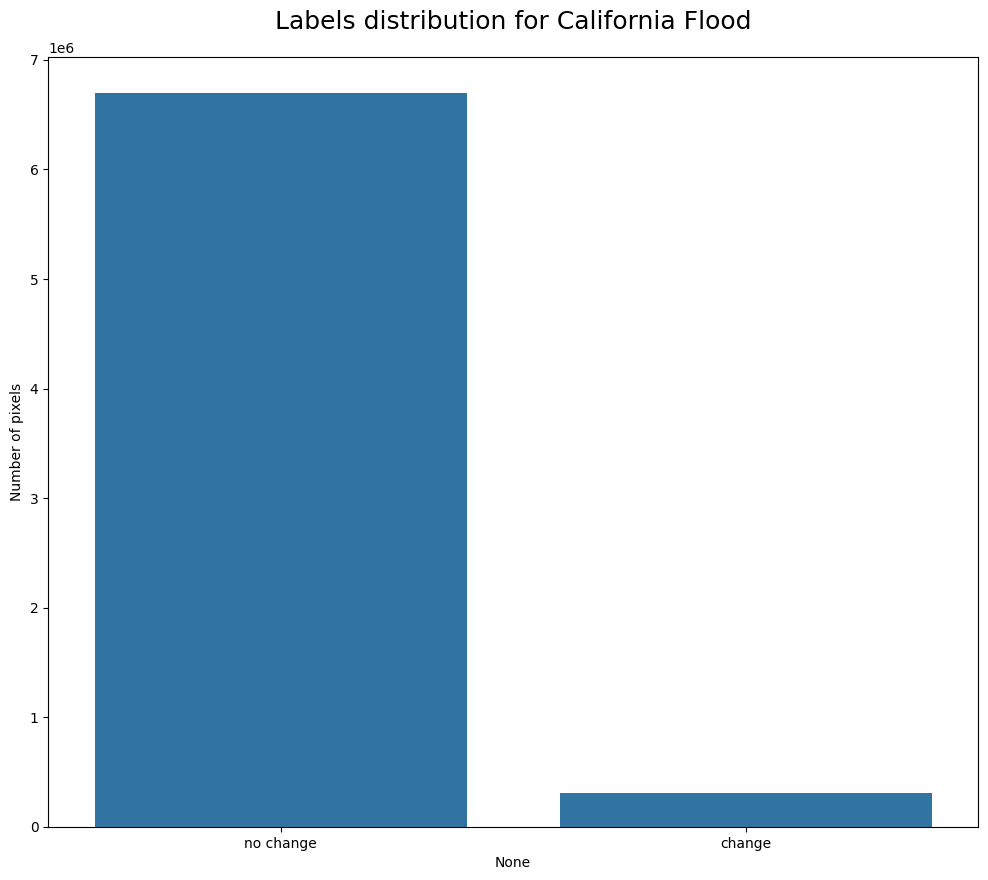

In [12]:
dataset.data_distribution_barchart();

Patches of the original image

Total number of patches: 73


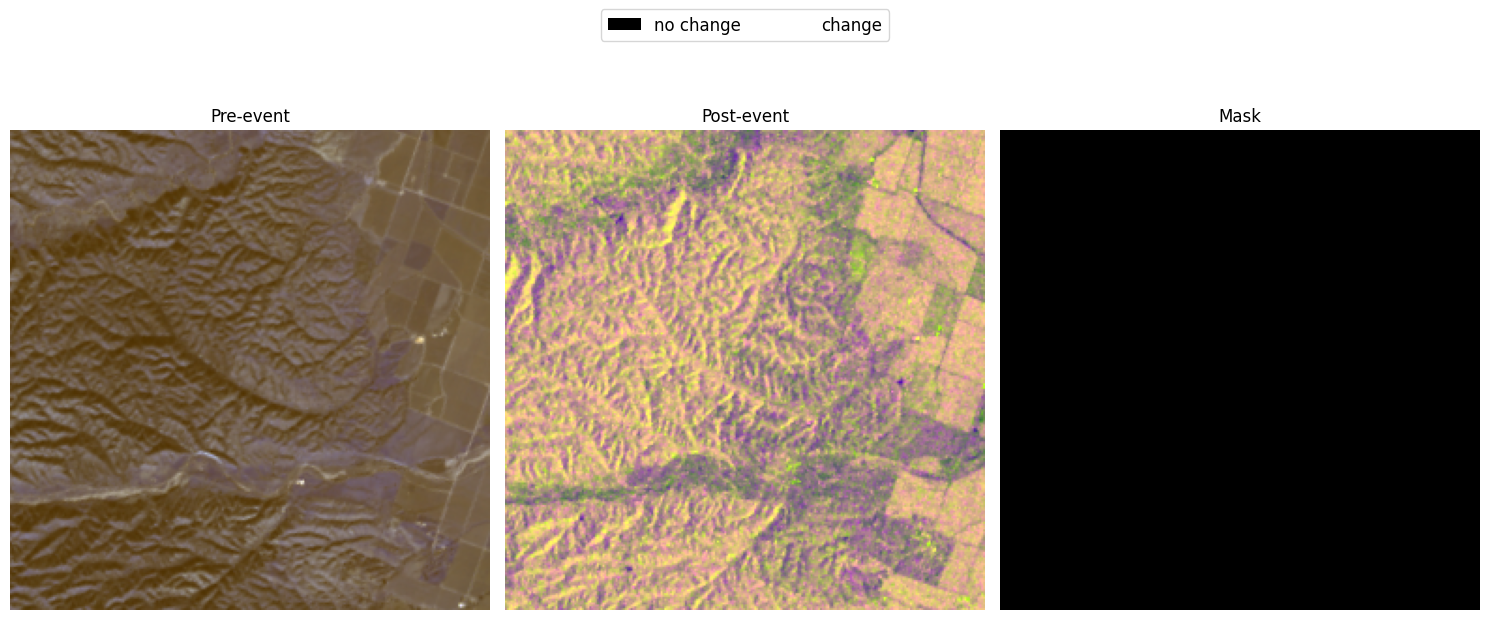

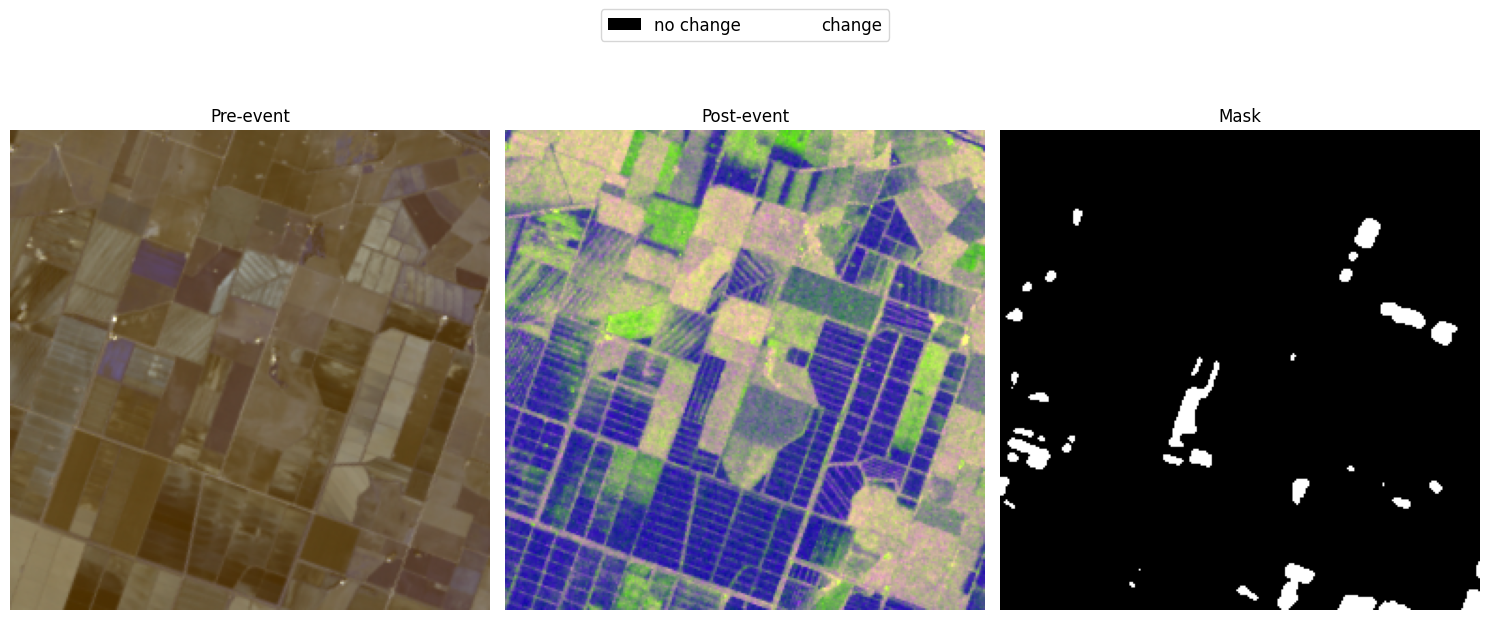

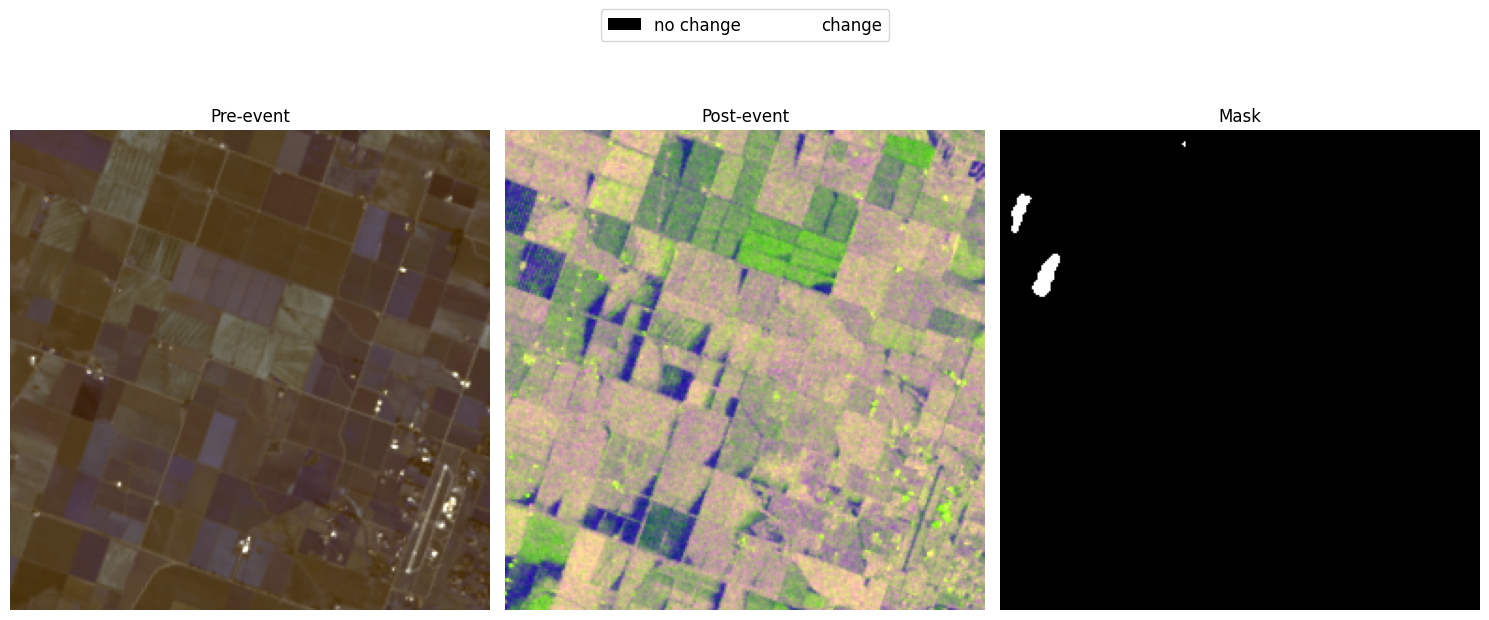

In [ ]:
dataset_config = {
    "data_dir" : "./data/california_flood/UiT_HCD_California_2017.mat",
    "selection": "rgb",
    "mode": "train"
}
dataset = CaliforniaFloodDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(0);
dataset.show_image(10);
dataset.show_image(50);

## Load training and test data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/california_flood/UiT_HCD_California_2017.mat",
    "selection": "rgb",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = CaliforniaFloodDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/california_flood/UiT_HCD_California_2017.mat",
    "selection": "rgb",
    "mode": "val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = CaliforniaFloodDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(73, 9)

## Create the model

In [ ]:
epochs = 50
model_directory = "./data/experiments/california_flood"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [7]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-27 11:58:33,434 INFO Starting training.
training: 100%|██████████| 10/10 [00:01<00:00,  5.61it/s]
2026-01-27 11:58:35,266 INFO epoch: 1, loss:  0.23211
testing on train set: 100%|██████████| 10/10 [00:00<00:00, 11.82it/s]
2026-01-27 11:58:37,304 INFO Accuracy:0.5000216340365475, Accuracy per Class:[0.96018668 0.03985658], Precision Micro:0.5000108172658613, Precision Macro:0.5000002841939731, Precision Weighted:0.9235435908329294, Precision per Class:[0.96018668 0.03981388], Recall Micro:0.9999987458529538, Recall Macro:0.9999842496534923, Recall Weighted:0.9999987458529538, Recall per Class:[1.        0.9999685], F1_score Micro:0.6666760032371417, F1_score Macro:0.5281338962698487, F1_score Weighted:0.9437332046643012, F1_score per Class:[0.97968902 0.07657877], IOU:0.5000105037153366, IOU mean:0.5000002592266287, IOU per Class:[0.96018668 0.03981383]
training: 100%|██████████| 10/10 [00:01<00:00,  7.28it/s]
2026-01-27 11:58:38,686 INFO epoch: 2, loss:  0.21482
testing on trai

## Predictions

2026-01-27 12:00:53,106 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/california_flood/checkpoint.pth.tar
2026-01-27 12:00:53,628 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/california_flood/checkpoint.pth.tar at epoch 51


9


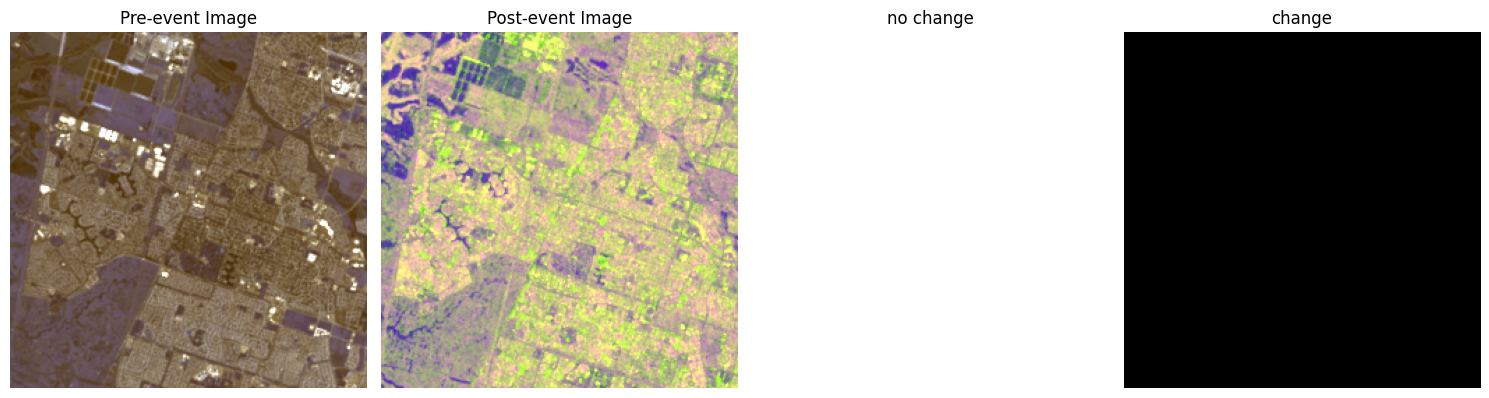

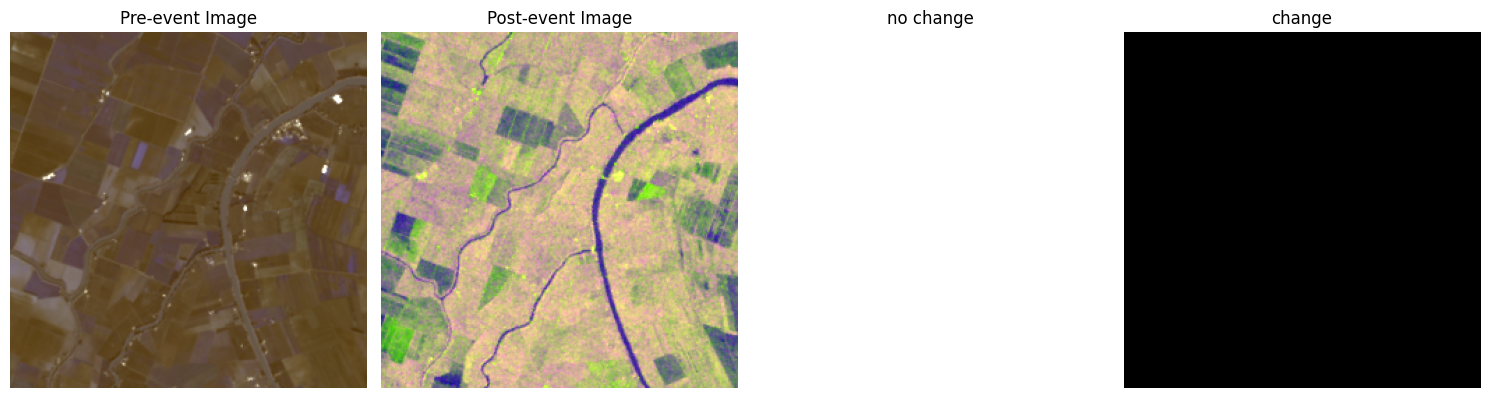

In [ ]:
model_path = "./data/experiments/california_flood/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir" : "./data/california_flood/UiT_HCD_California_2017.mat",
    "selection": "rgb",
    "mode": "test"
}
test_dataset = CaliforniaFloodDataset(test_dataset_config)
print(len(test_dataset))

image1 = test_dataset[0][0][0]
image2 = test_dataset[0][0][1]
fig = model.predict_masks(image1, image2, labels, transform)

image1 = test_dataset[5][0][0]
image2 = test_dataset[5][0][1]
fig = model.predict_masks(image1, image2, labels, transform)